# VERDE - Does ResNet Beat the Lightweight Models? (benchmark, 3.0 data)
### Smart Recycling and Waste Segregation Assistant - comparing ResNet-18, ResNet-34 and ResNet-50 with two lightweight models on the 3.0 waste photos

**Question:** With the wider 3.0 training data (61,824 images from five sources), does a classic ResNet classify waste better than the two lightweight models we have shortlisted (EfficientNet-B0 and MobileNetV3-Large), is any gain worth the extra size and CPU time on a Raspberry Pi, and do the new images help on the frozen 2.0 test set and on our own photos?

**Answer:** No. ResNets do not beat the lightweight models on the 3.0 data. The best ResNet (ResNet-50) scores 90.0% on the whole 3.0 test set (macro-F1 0.899), 3.0 points behind EfficientNet-B0 (93.0%, 0.928) and 1.6 behind MobileNetV3-Large (91.6%, 0.914), while its file is 5.9 times larger than B0's (94.1 against 16.1 MB), it takes 2.4 times as long on CPU (87 against 37 ms) and 2.2 times as long to train. ResNet-34 (89.1%) and ResNet-18 (88.5%) are further behind. The gap is widest on web-sourced images (Hugging Face: B0 89.3%, ResNet-50 84.6%), and on RealWaste, the source closest to the Pi camera, ResNet-50 trails B0 by 2.7 points (90.6% against 93.3%). In 2.0 the ResNets were about 1 point behind V3-Large; here they are 1.6 to 3.1 behind. Training on 3.0 instead of 2.0 changed no ResNet by more than 0.8 points on the 2.0 test images. The ResNets were still improving at epoch 12, so a longer run might narrow the gap, but it is unlikely to close 3 points.


<a id="section-1"></a>
## Section 1: Aim and Method

**Goal:** State what is being tested and why the comparison is fair, so the results can be trusted and explained.

**The models:**

| Model | Year | Idea |
|---|---|---|
| ResNet-18 | 2015 | Residual ("skip") connections let each block add to its input, which made deep networks trainable; 18 layers; about 11.7 M parameters |
| ResNet-34 | 2015 | The same design with 34 layers; about 21.8 M parameters |
| ResNet-50 | 2015 | 50 layers with bottleneck blocks; about 25.6 M parameters |
| EfficientNet-B0 | 2019 | **Reference.** The best model in the 3.0 EfficientNet benchmark (93.0% on the 3.0 test set); retrained here |
| MobileNetV3-Large | 2019 | **Reference.** The fastest of our shortlisted models (91.5 to 91.6% on the 3.0 test set in the earlier benchmarks); retrained here |

ResNets are a classic, widely used family but they were not designed for small devices. They need roughly 8 to 19 times the arithmetic of MobileNetV3-Large per photo (about 1.8 to 4.1 billion operations against 0.22 billion), and their files are much larger. The question is whether that extra capacity buys better accuracy on waste photos, and whether it is affordable on a Pi. The two reference models are retrained in this notebook so that every model is compared under identical conditions. Parameter counts above are for the original 1000-class ImageNet models; Section 4 shows the counts with our 8-class output layer.

**The 3.0 data** (built in the VERDE Data Analysis 3.0 notebook): the frozen 2.0 images (14,424, keeping their 2.0 train / validation / test split) plus 47,400 new images from GlobalWasteData and Hugging Face (split 70/15/15 on their own). Every new image was checked so that it is not a copy of a 2.0 test image or of one of our 24 real photos. The class order is unchanged.

**Why the test is fair:** every model gets the same photos, the same train / validation / test split, the same augmentation, the same loss function, the same optimiser and the same 12 epochs. The recipe is **identical to the 2.0 benchmark**, so a change from the 2.0 results comes from the data and not from the training settings. Only the network changes between the models.

**How results are judged:**
1. **Test accuracy and macro-F1** on photos the model never trained on, in three views: the whole 3.0 test set, the **2.0 test images only** (the same images as in the 2.0 benchmark, so a like-for-like comparison) and the new test images.
2. **Accuracy per data source.** RealWaste photos (real items on a floor) are the closest to what the Pi camera will see; GWD and HF are new and more varied.
3. **Size and CPU time per photo**, because the Pi has no GPU.
4. **Your own photos** (Section 9): the 24 real photos are scored automatically, and you can add more, because dataset scores are flattered by catalogue-style images.

**Terms used in this notebook:**

| Term | Plain meaning |
|---|---|
| Pretrained | The network already learned general shapes and textures from ImageNet, so we only need to adapt it to waste |
| Augmentation | Randomly zooming, rotating and recolouring training photos so the model does not rely on one lighting or background |
| Class weights | Rare classes count more in the loss, so a small class like `general` is not ignored (3.0 weights: 0.61 for `special` to 1.67 for `general`) |
| Residual connection | A shortcut that adds a block's input to its output, so very deep networks can still be trained |
| Overfitting | Doing much better on training photos than on new ones |
| Macro-F1 | One score in which every class counts equally, so big classes cannot hide a weak small class |
| Domain gap | The drop in accuracy when a model is tested on photos from a different source than it trained on |

<a id="section-2"></a>
## Section 2: Setup and Data

**Goal:** Load the exact split and class order created in the 3.0 data analysis notebook, so every model is compared on identical images and none of the test photos were used in training.

**Before you run:** attach two inputs to this notebook: the output of **VERDE Data Analysis 3.0** (it holds `final_dataset_v3_std.csv`, `dataset_card_v3.json` and `verde_std_new/`) and the output of **VERDE Data Analysis 2.0** (it holds `verde_std/` with the 2.0 images). Optionally attach your real-photo dataset (file names such as `glass_bottle_01.jpg`) for the automatic score in Section 9.

In [1]:
# ============================================================
# CELL 1 - SETUP AND DATA
# ============================================================

import json, random, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image, ImageOps
from tqdm import tqdm

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from torchvision import transforms
from torchvision.models import (resnet18, ResNet18_Weights,
                                resnet34, ResNet34_Weights,
                                resnet50, ResNet50_Weights,
                                efficientnet_b0, EfficientNet_B0_Weights,
                                mobilenet_v3_large, MobileNet_V3_Large_Weights)
from sklearn.metrics import confusion_matrix, f1_score

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

SEED = 42
INPUT = Path("/kaggle/input")
OUT = Path("/kaggle/working")

def find_folder(marker, max_depth=4):
    """Folder under /kaggle/input that contains the file `marker`."""
    for depth in range(1, max_depth + 1):
        hits = sorted(INPUT.glob("/".join(["*"] * depth) + "/" + marker))
        if hits:
            return hits[0].parent
    raise FileNotFoundError(f"{marker} not found under {INPUT}: attach the matching data-analysis notebook output "
                            f"in the Input panel.")

ROOT3 = find_folder("dataset_card_v3.json")        # VERDE Data Analysis 3.0 output
ROOT2 = find_folder("final_dataset_std.csv")       # VERDE Data Analysis 2.0 output
print("3.0 data:", ROOT3)
print("2.0 images:", ROOT2)

card = json.load(open(ROOT3 / "dataset_card_v3.json"))
class_names = card["classes"]
class_to_idx = {c: i for i, c in enumerate(class_names)}

df = pd.read_csv(ROOT3 / "final_dataset_v3_std.csv")
IMG_DIR = {"v2": ROOT2 / "verde_std", "new": ROOT3 / "verde_std_new"}
df["img"] = df["origin"].map(lambda o: str(IMG_DIR[o])) + "/" + df["rel_path"]
df["y"] = df["final_class"].map(class_to_idx)

# Fail early, with a clear message, if an image folder is not attached
for o in ["v2", "new"]:
    sample = df[df["origin"] == o].sample(min(200, (df["origin"] == o).sum()), random_state=SEED)["img"]
    missing = [p for p in sample if not Path(p).exists()]
    assert not missing, f"{len(missing)} of {len(sample)} sampled '{o}' images are missing, e.g. {missing[0]}"

train_df = df[df["split"] == "train"].reset_index(drop=True)
val_df = df[df["split"] == "val"].reset_index(drop=True)
test_df = df[df["split"] == "test"].reset_index(drop=True)

print(f"Train: {len(train_df)}  Val: {len(val_df)}  Test: {len(test_df)}  (total {len(df)})")
print("Classes:", class_to_idx)
display(pd.crosstab(df["src"], df["split"], margins=True))
display(pd.crosstab(df["final_class"], [df["origin"], df["split"]]).reindex(class_names))

3.0 data: /kaggle/input/notebooks/tanveerdalal/verde-data-analysis-3-0
2.0 images: /kaggle/input/notebooks/tanveerdalal/verde-data-analysis-2-0
Train: 43276  Val: 9274  Test: 9274  (total 61824)
Classes: {'food_garden': 0, 'general': 1, 'glass': 2, 'metal': 3, 'paper_card': 4, 'plastic': 5, 'special': 6, 'textile': 7}


split,test,train,val,All
src,,,,
Competition-only,412,2024,403,2839
GD,1064,4766,1005,6835
GWD,5317,24815,5317,35449
HF,1793,8365,1793,11951
RealWaste,688,3306,756,4750
All,9274,43276,9274,61824


origin        new               v2           
split        test train   val test train  val
final_class                                  
food_garden   733  3419   732  283  1318  282
general       480  2241   480  216  1008  216
glass         495  2313   496  267  1248  268
metal         802  3740   802  282  1313  281
paper_card   1053  4915  1053  324  1513  324
plastic       980  4571   979  309  1441  309
special      1758  8206  1759  149   696  150
textile       809  3775   809  334  1559  334

**Finding:** 61,824 images loaded and split into 43,276 train, 9,274 validation and 9,274 test, and the 2.0 rows kept their 2.0 split (2,164 test images). GlobalWasteData is 57% of the data, Hugging Face 19% and RealWaste, the source closest to a Pi camera, only 7.7% (4,750 of 61,824). `special` is the largest class, but only 149 of its test images come from 2.0 (against 1,758 new), so the 2.0 test set says little about `special` and the 3.0 test set is mostly new, web-sourced images.

<a id="section-3"></a>
## Section 3: Data Pipeline

**Goal:** Turn the photos into batches of numbers the models can read, using augmentation that weakens background and lighting shortcuts, and drawing the real floor photos (RealWaste) more often, as in 2.0.

In [2]:
# ============================================================
# CELL 2 - TRANSFORMS, DATASET AND LOADERS
# ============================================================
# WHAT: Define the training and evaluation transforms, the Dataset, and the data loaders.
# WHY:  The data analysis showed a model can learn the source's background or lighting
#       instead of the waste, and that models lose about 20 points when moved from one
#       source to another. Random zoom, rotation, colour change and greyscale make those
#       cues unreliable. Validation and test photos are never augmented. REALWASTE_BOOST = 2
#       is kept from 2.0 so the recipe is identical: each RealWaste photo is shown twice as
#       often. In 3.0 RealWaste is a smaller share of the data, so the boost matters less.
# HOW:  Each photo is already centre-cropped to 224x224. Augmentations are applied to the
#       training photos only. WeightedRandomSampler draws RealWaste with weight 2.
# ------------------------------------------------------------------------------------

IMG_SIZE = card["image_size"]            # 224
MEAN, STD = card["mean"], card["std"]    # ImageNet normalisation

train_transform = transforms.Compose([
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.7, 1.0), ratio=(0.9, 1.1)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=15, fill=160),
    transforms.ColorJitter(brightness=0.35, contrast=0.3, saturation=0.3, hue=0.03),
    transforms.RandomGrayscale(p=0.1),
    transforms.ToTensor(),
    transforms.Normalize(mean=MEAN, std=STD),
])
eval_transform = transforms.Compose([transforms.ToTensor(),
                                     transforms.Normalize(mean=MEAN, std=STD)])

class WasteDataset(Dataset):
    """One photo per row of a split table, with a transform applied."""
    def __init__(self, frame, transform):
        self.paths = frame["img"].tolist()
        self.labels = frame["y"].astype(int).tolist()
        self.transform = transform

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, i):
        with Image.open(self.paths[i]) as img:
            img = img.convert("RGB")
        return self.transform(img), self.labels[i]

BATCH_SIZE = 64            # if CUDA runs out of memory (ResNet-50), use 32
REALWASTE_BOOST = 2.0
NUM_WORKERS = 4

def make_train_loader():
    """A new training loader; the sampler's random draws are fixed by SEED."""
    g = torch.Generator()
    g.manual_seed(SEED)
    w = np.where(train_df["src"] == "RealWaste", REALWASTE_BOOST, 1.0)
    sampler = WeightedRandomSampler(torch.tensor(w, dtype=torch.double),
                                    num_samples=len(train_df), replacement=True,
                                    generator=g)
    return DataLoader(WasteDataset(train_df, train_transform), batch_size=BATCH_SIZE,
                      sampler=sampler, drop_last=True, num_workers=NUM_WORKERS,
                      pin_memory=True, persistent_workers=True)

val_loader = DataLoader(WasteDataset(val_df, eval_transform), batch_size=BATCH_SIZE,
                        shuffle=False, num_workers=NUM_WORKERS, pin_memory=True)
test_loader = DataLoader(WasteDataset(test_df, eval_transform), batch_size=BATCH_SIZE,
                         shuffle=False, num_workers=NUM_WORKERS, pin_memory=True)

x0, y0 = WasteDataset(train_df, train_transform)[0]
print(f"One training photo: tensor {tuple(x0.shape)}, class {class_names[y0]}")
print(f"Batches per epoch: {len(train_df) // BATCH_SIZE}")

# Share of each source in one epoch, without and with the RealWaste boost
w = np.where(train_df["src"] == "RealWaste", REALWASTE_BOOST, 1.0)
share = pd.DataFrame({"natural share": train_df["src"].value_counts(normalize=True),
                      "share per epoch": pd.Series(w, index=train_df.index).groupby(train_df["src"]).sum() / w.sum()})
display((share * 100).round(1))

One training photo: tensor (3, 224, 224), class glass
Batches per epoch: 676


,natural share,share per epoch
src,,
Competition-only,4.7,4.3
GD,11.0,10.2
GWD,57.3,53.3
HF,19.3,18.0
RealWaste,7.6,14.2


**Finding:** One epoch has 676 batches. RealWaste is 7.6% of the training images, and the boost of 2 raises its share of each epoch to 14.2%; GWD is still 53% of what the model sees. The boost matters less than in 2.0, where RealWaste was a third of the data (4,750 of 14,424 images). It was kept only to keep the recipe identical and was not re-tuned for 3.0.

<a id="section-4"></a>
## Section 4: The Candidate Models

**Goal:** Build the five networks with an 8-class output (three ResNets and two lightweight references), and compare their size and CPU speed before any training. Speed is measured with 4 threads, like the four cores of a Raspberry Pi 5. This is a Kaggle CPU, so the times are faster than a Pi; use them to compare the models with each other. All models run at 224x224, the size they were designed for. These numbers do not depend on the data, so they should match the 2.0 benchmark.

In [3]:
# ============================================================
# CELL 3 - THE CANDIDATE MODELS: SIZE AND CPU SPEED
# ============================================================
# WHAT: List the three models, define build_model(name), and measure each model's number of
#       parameters, file size and CPU time per photo.
# WHY:  The Pi has no GPU, so the real cost of a bigger model is CPU time and memory. This
#       shows what accuracy gain would need to be worth paying for. All models start from
#       ImageNet weights (version V1) so the starting point is comparable.
# HOW:  The last Linear layer of each network (1000 ImageNet classes) is replaced by an
#       8-class layer. CPU time is the average of 40 single-photo forward passes.
# ------------------------------------------------------------------------------------

MODELS = {
    "resnet18":  (resnet18, ResNet18_Weights.IMAGENET1K_V1),
    "resnet34":  (resnet34, ResNet34_Weights.IMAGENET1K_V1),
    "resnet50":  (resnet50, ResNet50_Weights.IMAGENET1K_V1),
    "effnet_b0": (efficientnet_b0, EfficientNet_B0_Weights.IMAGENET1K_V1),         # reference
    "v3_large":  (mobilenet_v3_large, MobileNet_V3_Large_Weights.IMAGENET1K_V1),   # reference
}
RUN = list(MODELS)         # models to train; use a shorter list to run fewer
EPOCHS = 12

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

def build_model(name, pretrained=True):
    """A network with an 8-class output layer."""
    make, weights = MODELS[name]
    net = make(weights=weights if pretrained else None)
    if hasattr(net, "fc"):                      # ResNet: the last layer is called fc
        net.fc = nn.Linear(net.fc.in_features, len(class_names))
    else:                                       # MobileNet / EfficientNet: last Linear in classifier
        last = max(i for i, m in enumerate(net.classifier) if isinstance(m, nn.Linear))
        net.classifier[last] = nn.Linear(net.classifier[last].in_features, len(class_names))
    return net

def cpu_ms_per_photo(name, threads=4, runs=40):
    """Average CPU time for one 224x224 photo."""
    old = torch.get_num_threads()
    torch.set_num_threads(threads)
    net = build_model(name, pretrained=False).eval()
    x = torch.randn(1, 3, IMG_SIZE, IMG_SIZE)
    with torch.no_grad():
        for _ in range(8):
            net(x)
        t = time.perf_counter()
        for _ in range(runs):
            net(x)
    torch.set_num_threads(old)
    return (time.perf_counter() - t) / runs * 1000

rows = []
for name in MODELS:
    n = sum(p.numel() for p in build_model(name, pretrained=False).parameters())
    rows.append({"model": name, "params (M)": n / 1e6, "size (MB)": n * 4 / 1e6,
                 "CPU ms/photo": cpu_ms_per_photo(name)})
spec = pd.DataFrame(rows).set_index("model").round(2)
display(spec)

Using device: cuda


,params (M),size (MB),CPU ms/photo
model,,,
resnet18,11.18,44.72,31.15
resnet34,21.29,85.16,54.83
resnet50,23.52,94.10,71.43
effnet_b0,4.02,16.07,29.37
v3_large,4.21,16.85,21.33


**Finding:** Parameters and file sizes match the 2.0 benchmark: ResNet-18 11.18 M (44.7 MB), ResNet-34 21.29 M (85.2 MB), ResNet-50 23.52 M (94.1 MB), B0 4.02 M (16.1 MB), V3-Large 4.21 M (16.9 MB). CPU time per photo is 33.2, 67.8 and 87.3 ms for the three ResNets, against 36.6 ms for B0 and 27.6 ms for V3-Large. These times are 5 to 30% higher than in 2.0 (the Kaggle CPU differs between runs), but the ratios hold: ResNet-18 takes about the same time as B0, ResNet-34 1.9 times and ResNet-50 2.4 times as long, and ResNet-50 takes 3.2 times V3-Large's time. ResNet-50's file is 5.9 times B0's and 5.6 times V3-Large's. These are Kaggle CPU times; the Pi will be slower, so the real time must be measured on the device.

<a id="section-5"></a>
## Section 5: Training

**Goal:** Train every model with the identical recipe and keep each model's best checkpoint, chosen by validation macro-F1. The training set is about four times larger than in 2.0 (43,276 images against 10,096), so each model takes roughly four times longer than in 2.0 (about 12 minutes for ResNet-18, ResNet-34, EfficientNet-B0 and V3-Large, 21.5 for ResNet-50). The MobileNet runs on the 3.0 data took 40 to 45 minutes each; plan for about 45 minutes each for ResNet-18, ResNet-34, B0 and V3-Large and about 85 minutes for ResNet-50, so about 4.5 hours for all five (an estimate). If your GPU quota is short, set `RUN` to fewer models (for example, `RUN = ["resnet18", "resnet50"]`); trained models are skipped when you rerun.

In [4]:
# ============================================================
# CELL 4 - ONE EPOCH AND THE TRAINING FUNCTION
# ============================================================
# WHAT: Define how one epoch runs, and a train_model(name) function that trains one model
#       for 12 epochs and saves its best checkpoint.
# WHY:  The same recipe for every model makes the comparison fair, and the same recipe as 2.0
#       makes the data the only change: loss with the 3.0 class weights (0.61 to 1.67) and
#       label smoothing 0.1 (stops the model being over-sure on look-alike items such as clear
#       plastic and glass), AdamW optimiser with learning rate 3e-4, and a cosine schedule
#       that lowers the rate smoothly. The best epoch is chosen on the validation set, so the
#       test set stays untouched for the final measurement.
# HOW:  model.train() for training; model.eval() with no gradients for validation. The
#       checkpoint stores the class names and the model name next to the weights, so
#       later notebooks can rebuild the right network from the file alone. File names start with
#       verde3_ so they cannot be mixed up with the 2.0 checkpoints.
# ------------------------------------------------------------------------------------

class_w = torch.tensor(card["class_weights_v3_train"], dtype=torch.float32, device=device)
print("Class weights:", dict(zip(class_names, [round(float(v), 2) for v in class_w.cpu()])))
criterion = nn.CrossEntropyLoss(weight=class_w, label_smoothing=0.1)

def run_epoch(model, loader, optimizer=None):
    """One pass over a loader. Trains if an optimiser is given, otherwise evaluates."""
    train = optimizer is not None
    model.train() if train else model.eval()
    total, n, preds, labels = 0.0, 0, [], []
    with torch.set_grad_enabled(train):
        for x, y in tqdm(loader, leave=False):
            x, y = x.to(device), y.to(device)
            out = model(x)
            loss = criterion(out, y)
            if train:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
            total += loss.item() * x.size(0)
            n += x.size(0)
            preds += out.argmax(1).cpu().tolist()
            labels += y.cpu().tolist()
    acc = float(np.mean(np.array(preds) == np.array(labels)))
    return total / n, acc, np.array(preds), np.array(labels)

def ckpt_path(name):
    return OUT / f"verde3_{name}.pth"

def train_model(name):
    """Train one model; return its per-epoch history and training time."""
    random.seed(SEED); np.random.seed(SEED)
    torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)

    model = build_model(name).to(device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=3e-4, weight_decay=1e-4)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)
    train_loader = make_train_loader()

    hist = {"train_acc": [], "val_acc": [], "val_f1": []}
    best_f1, t0 = 0.0, time.time()
    for epoch in range(1, EPOCHS + 1):
        _, tr_acc, _, _ = run_epoch(model, train_loader, optimizer)
        _, va_acc, vp, vy = run_epoch(model, val_loader)
        va_f1 = f1_score(vy, vp, average="macro")
        scheduler.step()
        hist["train_acc"].append(tr_acc)
        hist["val_acc"].append(va_acc)
        hist["val_f1"].append(va_f1)

        mark = ""
        if va_f1 > best_f1:
            best_f1, mark = va_f1, " <- best"
            torch.save({"model_state": model.state_dict(), "class_names": class_names,
                        "arch": name, "epoch": epoch, "val_acc": va_acc,
                        "val_f1": va_f1, "data": "3.0"}, ckpt_path(name))
        print(f"{name} epoch {epoch:2d}/{EPOCHS}  train {tr_acc:.1%}  "
              f"val {va_acc:.1%}  F1 {va_f1:.3f}{mark}")

    del model, optimizer, train_loader
    torch.cuda.empty_cache()
    return {"history": hist, "minutes": (time.time() - t0) / 60}

Class weights: {'food_garden': 1.14, 'general': 1.66, 'glass': 1.52, 'metal': 1.07, 'paper_card': 0.84, 'plastic': 0.9, 'special': 0.61, 'textile': 1.01}


In [5]:
# ============================================================
# CELL 5 - TRAIN EACH MODEL
# ============================================================
# WHAT: Train each model in RUN and keep its history in benchmark3_runs.json.
# WHY:  Training takes a while. Results are saved after each model, and a model that is
#       already trained is skipped, so a stopped session can continue instead of restarting.
#       Delete benchmark3_runs.json (and the verde3_*.pth files) to retrain from scratch.
#       If an "Exception ignored" message from the data loader appears, it is harmless.
# HOW:  One loop; the printed lines show train and validation accuracy per epoch.
# ------------------------------------------------------------------------------------

RUNS_PATH = OUT / "benchmark3_runs.json"
runs = json.load(open(RUNS_PATH)) if RUNS_PATH.exists() else {}

for name in RUN:
    if name in runs and ckpt_path(name).exists():
        print(f"Skipping {name}: already trained")
        continue
    print(f"\n=== Training {name} ===")
    runs[name] = train_model(name)
    json.dump(runs, open(RUNS_PATH, "w"))
    print(f"{name}: best val F1 {max(runs[name]['history']['val_f1']):.3f}, "
          f"{runs[name]['minutes']:.1f} min")


=== Training resnet18 ===
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 198MB/s]


resnet18 epoch  1/12  train 71.6%  val 76.5%  F1 0.762 <- best


resnet18 epoch  2/12  train 79.7%  val 80.4%  F1 0.797 <- best


resnet18 epoch  3/12  train 82.9%  val 77.2%  F1 0.773


resnet18 epoch  4/12  train 86.0%  val 81.2%  F1 0.809 <- best


... (56 outputs left out)

v3_large epoch  9/12  train 98.0%  val 91.1%  F1 0.910 <- best


v3_large epoch 10/12  train 98.3%  val 91.5%  F1 0.912 <- best


v3_large epoch 11/12  train 98.4%  val 91.6%  F1 0.913 <- best


v3_large epoch 12/12  train 98.7%  val 91.6%  F1 0.913 <- best
v3_large: best val F1 0.913, 38.2 min


**Finding:** All five models trained without problems and all five peaked at the last epoch (epoch 12). Best validation macro-F1: ResNet-18 0.883, ResNet-34 0.887, ResNet-50 0.896, B0 0.924, V3-Large 0.913. The ResNets start more slowly: in epoch 1 their validation accuracy is 78.4% (ResNet-18), 70.2% (ResNet-34) and 77.6% (ResNet-50), against 85.5% for B0 and 84.2% for V3-Large. Training took 47.2, 51.7, 106.0, 47.8 and 37.1 minutes, 4.8 hours in total (the estimate was about 4.5). ResNet-50 took 2.2 times as long as B0. These validation scores are not comparable with 2.0, because the validation set now includes 7,110 new images; the like-for-like comparison is in Section 7.

<a id="section-6"></a>
## Section 6: Learning Curves

**Goal:** Check whether the models learn steadily, whether they overfit, and whether 12 epochs were enough.

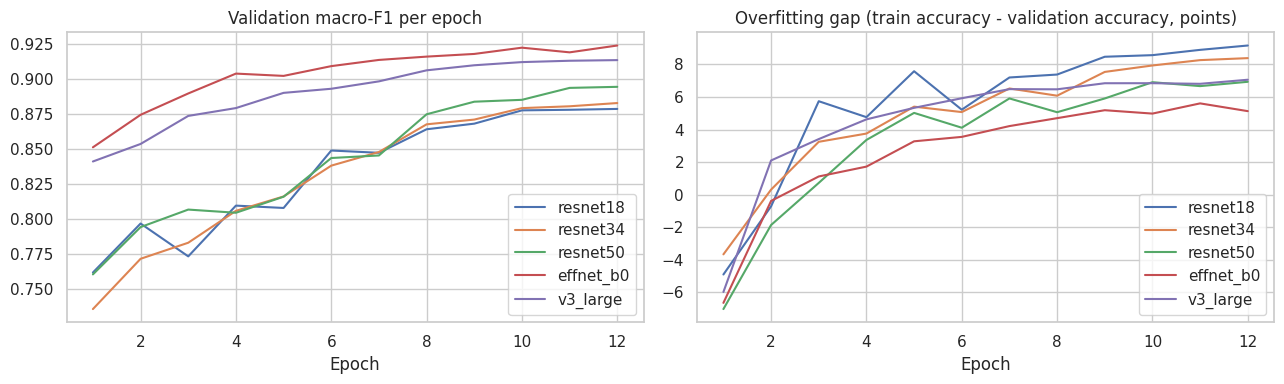

Gain in validation macro-F1 over the last three epochs: {'resnet18': 0.0105, 'resnet34': 0.0118, 'resnet50': 0.0106, 'effnet_b0': 0.006, 'v3_large': 0.0037}
Final overfitting gap (points): {'resnet18': 9.2, 'resnet34': 8.4, 'resnet50': 6.9, 'effnet_b0': 5.1, 'v3_large': 7.1}


In [6]:
# ============================================================
# CELL 6 - LEARNING CURVES
# ============================================================
# WHAT: Plot each model's validation macro-F1 and its overfitting gap per epoch.
# WHY:  A gap that widens between training and validation accuracy is the standard sign of
#       overfitting. If validation is still rising at epoch 12, more epochs could help; if it
#       is flat, 12 was enough. With four times more images per epoch, the models see far more
#       updates than in 2.0, so they may converge earlier.
# HOW:  Gap = training accuracy minus validation accuracy, in percentage points.
# ------------------------------------------------------------------------------------

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for name in RUN:
    h = runs[name]["history"]
    ep = range(1, len(h["val_f1"]) + 1)
    axes[0].plot(ep, h["val_f1"], label=name)
    axes[1].plot(ep, (np.array(h["train_acc"]) - np.array(h["val_acc"])) * 100, label=name)
axes[0].set_title("Validation macro-F1 per epoch")
axes[1].set_title("Overfitting gap (train accuracy - validation accuracy, points)")
for ax in axes:
    ax.set_xlabel("Epoch"); ax.legend()
plt.tight_layout()
plt.savefig(OUT / "benchmark3_curves.png", dpi=150, bbox_inches="tight")
plt.show()

last3 = {n: round(runs[n]["history"]["val_f1"][-1] - runs[n]["history"]["val_f1"][max(-4, -len(runs[n]["history"]["val_f1"]))], 4) for n in RUN}
gap = {n: round((runs[n]["history"]["train_acc"][-1] - runs[n]["history"]["val_acc"][-1]) * 100, 1) for n in RUN}
print("Gain in validation macro-F1 over the last three epochs:", last3)
print("Final overfitting gap (points):", gap)

**Finding:** Validation macro-F1 was still rising at epoch 12, most for the deepest ResNets: the gain over the last three epochs is +0.020 for ResNet-50, +0.013 for ResNet-34 and +0.007 for ResNet-18, against +0.006 for B0 and +0.005 for V3-Large. The final overfitting gap is 8.8 points for ResNet-18, 8.0 for ResNet-34, 6.8 for ResNet-50, 5.1 for B0 and 7.0 for V3-Large, so the ResNets overfit more than B0. The learning rate reaches zero at epoch 12 by design, so "more epochs" would mean a new schedule. It might help ResNet-50 most, but this run gives no sign that it would close a 3-point gap; the 2.0 ResNets were also still improving at epoch 12 and still finished behind.

<a id="section-7"></a>
## Section 7: Test Results

**Goal:** Measure each model once on the held-out test set. The 3.0 test set mixes 2.0 images with new GWD and HF images, so the score is shown three ways: on the whole 3.0 test set, on the **2.0 test images only** (identical to the 2.0 benchmark, so it shows whether the new training data helped or hurt on the old yardstick), and per data source.

In [7]:
# ============================================================
# CELL 7 - TEST RESULTS PER MODEL, SUBSET AND SOURCE
# ============================================================
# WHAT: Load each model's best checkpoint, predict the test set, and build one results table.
# WHY:  The test photos were never used for training or for choosing the best epoch, so
#       this is the honest dataset-level comparison. The 2.0-only subset is the same set of
#       images the 2.0 models were tested on. Plastic and special recall are included because
#       plastic was the weak point of the 2.0 model and special is the largest and noisiest
#       class in 3.0. The two plastic mistakes (plastic called metal, plastic called glass)
#       are counted on the whole test set.
# HOW:  Predictions are collected with gradients off. Per-class recall (the share of each
#       class's test photos that were found) is kept for the heatmaps below, on the whole
#       test set and on the 2.0 subset.
# ------------------------------------------------------------------------------------

def load_net(name):
    ck = torch.load(ckpt_path(name), map_location=device)
    net = build_model(name, pretrained=False).to(device)
    net.load_state_dict(ck["model_state"])
    return net.eval(), ck

ip, ig, im, isp = (class_to_idx[c] for c in ["plastic", "glass", "metal", "special"])
SOURCES = {"RealWaste": "RealWaste", "GD": "GD", "Competition-only": "Competition", "GWD": "GWD", "HF": "HF"}
is_v2 = (test_df["origin"] == "v2").to_numpy()
labels_all = list(range(len(class_names)))
table, recall, recall_v2 = [], {}, {}
for name in RUN:
    net, ck = load_net(name)
    _, acc, p, y = run_epoch(net, test_loader)
    del net
    ok = pd.Series(p == y, index=test_df.index)
    by_src = ok.groupby(test_df["src"]).mean()
    cm = confusion_matrix(y, p, labels=labels_all)
    cm2 = confusion_matrix(y[is_v2], p[is_v2], labels=labels_all)
    recall[name] = cm.diagonal() / cm.sum(axis=1)
    recall_v2[name] = cm2.diagonal() / cm2.sum(axis=1)
    row = {"model": name, "best epoch": ck["epoch"], "test acc": acc,
           "test F1": f1_score(y, p, average="macro"),
           "2.0-test acc": float(ok[is_v2].mean()),
           "2.0-test F1": f1_score(y[is_v2], p[is_v2], average="macro"),
           "new-test acc": float(ok[~is_v2].mean())}
    for src, label in SOURCES.items():
        row[label] = float(by_src.get(src, np.nan))
    row.update({"plastic recall": recall[name][ip], "special recall": recall[name][isp],
                "plastic->metal": int(cm[ip, im]), "plastic->glass": int(cm[ip, ig]),
                "train min": runs[name]["minutes"]})
    table.append(row)
torch.cuda.empty_cache()

results = pd.DataFrame(table).set_index("model").join(spec)
print(f"Test images: {len(test_df)} (2.0 images {int(is_v2.sum())}, new images {int((~is_v2).sum())})")
display(results.round(3).T)

Test images: 9274 (2.0 images 2164, new images 7110)


model,resnet18,resnet34,resnet50,effnet_b0,v3_large
best epoch,12.000,12.000,12.000,12.000,12.000
test acc,0.888,0.888,0.898,0.930,0.916
test F1,0.886,0.886,0.896,0.927,0.913
2.0-test acc,0.918,0.917,0.921,0.943,0.933
2.0-test F1,0.914,0.914,0.918,0.940,0.930
new-test acc,0.879,0.879,0.891,0.926,0.910
RealWaste,0.897,0.906,0.910,0.933,0.922
GD,0.921,0.916,0.918,0.943,0.928
Competition,0.944,0.939,0.947,0.961,0.966
GWD,0.895,0.897,0.907,0.937,0.926


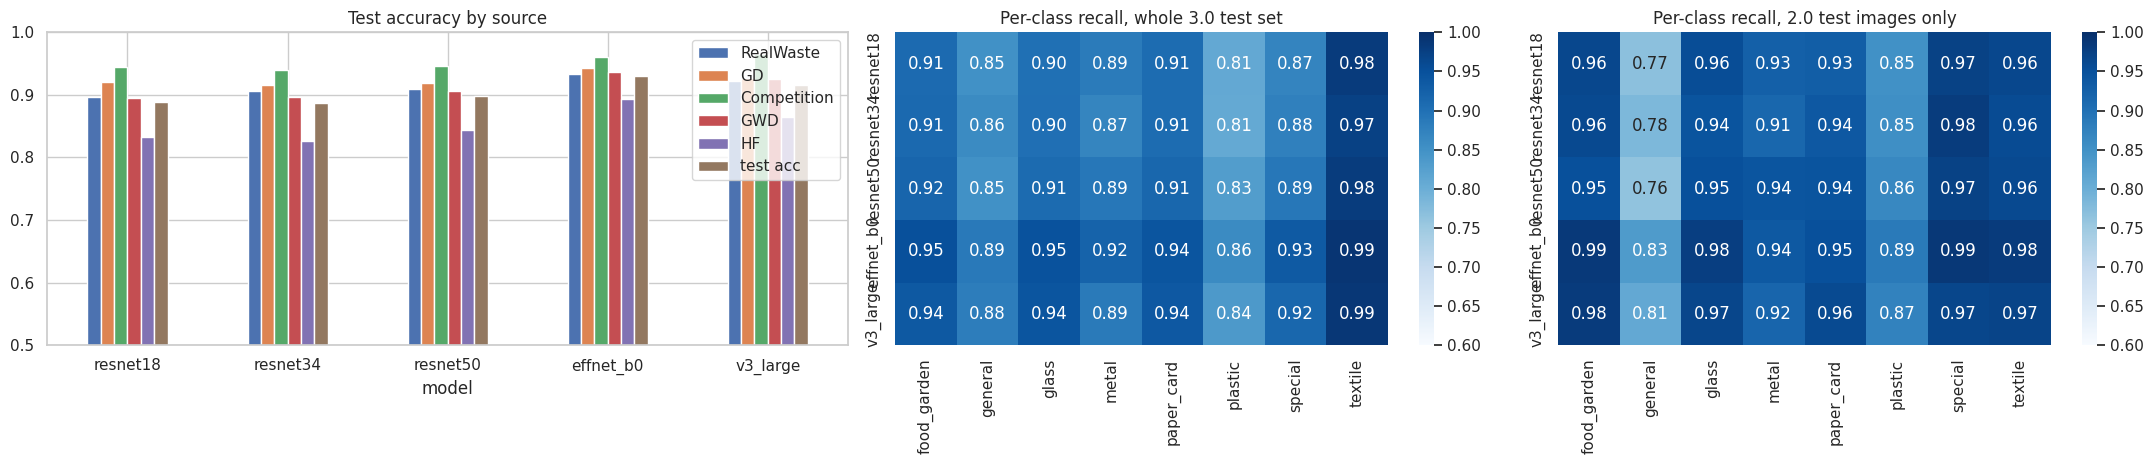

In [8]:
# ============================================================
# CELL 8 - ACCURACY BY SOURCE AND PER-CLASS RECALL
# ============================================================
# WHAT: Draw accuracy by source as grouped bars, and per-class recall as two heatmaps (whole
#       3.0 test set, and the 2.0 test images only).
# WHY:  The bars show whether a model's gain is on the real floor photos or only on the new
#       catalogue-style sources. The heatmaps show which classes each model is better or
#       worse at, especially plastic, glass, metal, general and special.
# HOW:  Each bar group is one model; each heatmap row is one model.
# ------------------------------------------------------------------------------------

fig, axes = plt.subplots(1, 3, figsize=(22, 4.8), gridspec_kw={"width_ratios": [1.3, 1, 1]})
cols = ["RealWaste", "GD", "Competition", "GWD", "HF", "test acc"]
results[cols].plot.bar(ax=axes[0], rot=0)
axes[0].set_ylim(0.5, 1.0)
axes[0].set_title("Test accuracy by source")
sns.heatmap(pd.DataFrame(recall, index=class_names).T, annot=True, fmt=".2f",
            cmap="Blues", vmin=0.6, vmax=1, ax=axes[1])
axes[1].set_title("Per-class recall, whole 3.0 test set")
sns.heatmap(pd.DataFrame(recall_v2, index=class_names).T, annot=True, fmt=".2f",
            cmap="Blues", vmin=0.6, vmax=1, ax=axes[2])
axes[2].set_title("Per-class recall, 2.0 test images only")
plt.tight_layout()
plt.savefig(OUT / "benchmark3_test.png", dpi=150, bbox_inches="tight")
plt.show()

,2.0-trained acc,2.0-trained F1,3.0-trained acc,3.0-trained F1,acc delta (points),F1 delta (points)
resnet18,0.922,0.921,0.918,0.914,-0.426,-0.720
resnet34,0.921,0.922,0.917,0.914,-0.372,-0.781
resnet50,0.922,0.923,0.921,0.918,-0.102,-0.531
effnet_b0,0.943,0.943,0.943,0.940,0.016,-0.295
v3_large,0.932,0.930,0.933,0.930,0.099,-0.030


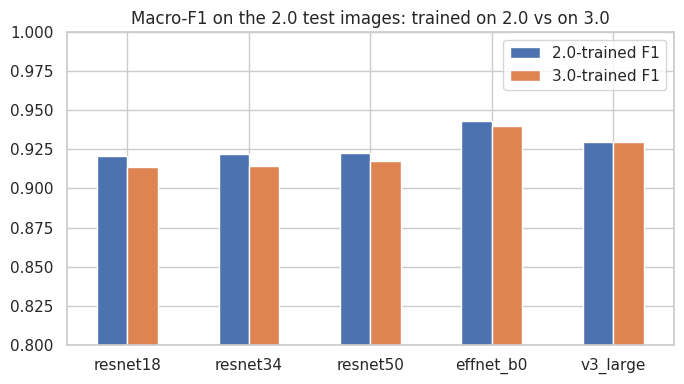

In [9]:
# ============================================================
# CELL 9 - 3.0-TRAINED VS 2.0-TRAINED, ON THE SAME 2.0 TEST IMAGES
# ============================================================
# WHAT: Compare each model trained on 3.0 with the same model trained on 2.0, using only the
#       2.0 test images.
# WHY:  This is the main question of the 3.0 work: do 47,400 new images help on the old
#       yardstick? The 2.0 values are copied from the 2.0 benchmark notebook (one run per
#       model, seed 42, same recipe, from the 2.0 ResNet benchmark notebook), so they are fixed numbers, not retrained here. One run
#       has about 1 to 2 points of noise, so only a clear gap should be believed.
# HOW:  Delta = 3.0-trained minus 2.0-trained, in percentage points.
# ------------------------------------------------------------------------------------

REF_2_0 = pd.DataFrame({"2.0-trained acc": {"resnet18": 0.922, "resnet34": 0.921, "resnet50": 0.922, "effnet_b0": 0.943, "v3_large": 0.932},
                        "2.0-trained F1":  {"resnet18": 0.921, "resnet34": 0.922, "resnet50": 0.923, "effnet_b0": 0.943, "v3_large": 0.930}})
cmp = REF_2_0.join(results[["2.0-test acc", "2.0-test F1"]].rename(
    columns={"2.0-test acc": "3.0-trained acc", "2.0-test F1": "3.0-trained F1"}))
cmp["acc delta (points)"] = (cmp["3.0-trained acc"] - cmp["2.0-trained acc"]) * 100
cmp["F1 delta (points)"] = (cmp["3.0-trained F1"] - cmp["2.0-trained F1"]) * 100
display(cmp.loc[RUN].round(3))

ax = cmp.loc[RUN, ["2.0-trained F1", "3.0-trained F1"]].plot.bar(rot=0, figsize=(7, 4))
ax.set_ylim(0.8, 1.0)
ax.set_title("Macro-F1 on the 2.0 test images: trained on 2.0 vs on 3.0")
plt.tight_layout(); plt.show()

**Finding:** **All three ResNets finish below both lightweight models.** On the 9,274 test images ResNet-50 scores 90.0% accuracy and 0.899 macro-F1, ResNet-34 89.1% and 0.889, and ResNet-18 88.5% and 0.881, against 93.0% and 0.928 for B0 and 91.6% and 0.914 for V3-Large. Depth helps a little inside the family (+0.6 points from ResNet-18 to 34 and +0.9 from 34 to 50) but far less than the gap to B0, which is 3.0 points for ResNet-50, about 280 test images.

**The gap is widest on web-sourced images.** On the identical 2,164 images of the 2.0 test set, ResNet-50 scores 92.2% against 94.3% for B0 and 93.7% for V3-Large; on the new test images it scores 89.3% against 92.6% and 91.0%. By source, the Hugging Face gap is the largest: ResNet-18 81.8%, ResNet-34 83.0% and ResNet-50 84.6%, against 89.3% for B0 and 85.6% for V3-Large. On RealWaste, the source closest to the Pi camera, ResNet-50 scores 90.6% against 93.3% for B0 and 92.9% for V3-Large, about 19 photos out of 688. On Competition-only (412 photos) the ResNets score 94.2 to 94.4% against 96.1% for B0 and 96.8% for V3-Large.

**3.0 training did not clearly help on the 2.0 test images.** Compared with the same model trained on 2.0, accuracy on the 2.0 test images changes by -0.8 points for ResNet-18, 0.0 for ResNet-34 and ResNet-50, 0.0 for B0 and +0.5 for V3-Large, with one run per model and 1 to 2 points of noise. This repeats the MobileNet and EfficientNet results.

**Weak spots.** Depth did not fix plastic, the hardest class: its recall is 0.813 for ResNet-18, 0.824 for ResNet-34 and 0.836 for ResNet-50, against 0.860 for B0 and 0.842 for V3-Large. The ResNets call plastic images metal more often (60 to 67 times against 42 to 49 for the lightweight models) but glass slightly less often (25 to 31 against 36 to 37). `special` recall is 0.868 to 0.895 for the ResNets against 0.935 for B0 and 0.916 for V3-Large.

<a id="section-8"></a>
## Section 8: Accuracy vs Speed

**Goal:** Put accuracy and speed on one chart. A model that is slightly more accurate but much slower may not be worth it on a Raspberry Pi.

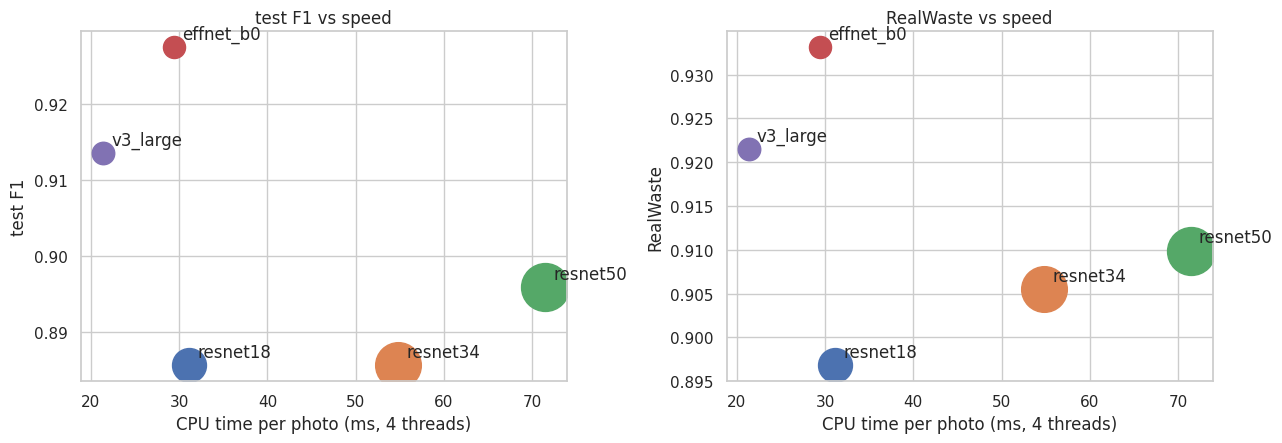

In [10]:
# ============================================================
# CELL 10 - ACCURACY VS SPEED
# ============================================================
# WHAT: Plot CPU time per photo (x) against test macro-F1 and RealWaste accuracy (y).
# WHY:  The Pi has a time and memory budget, so the best model is the one that is accurate
#       enough and fast enough, not simply the most accurate.
# HOW:  One point per model; up and to the left is better. Larger markers are larger files.
# ------------------------------------------------------------------------------------

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
for ax, col in zip(axes, ["test F1", "RealWaste"]):
    for name, r in results.iterrows():
        ax.scatter(r["CPU ms/photo"], r[col], s=60 + r["size (MB)"] * 12)
        ax.annotate(name, (r["CPU ms/photo"], r[col]), xytext=(6, 6),
                    textcoords="offset points")
    ax.set_xlabel("CPU time per photo (ms, 4 threads)")
    ax.set_ylabel(col)
    ax.set_title(f"{col} vs speed")
plt.tight_layout(); plt.show()

**Finding:** Every ResNet is beaten on both axes by a lightweight model. V3-Large is faster (27.6 ms) and more accurate (macro-F1 0.914) than all three ResNets, and B0 is more accurate than all three and faster than ResNet-34 and ResNet-50. The closest case is ResNet-18, which takes about the same time as B0 (33.2 against 36.6 ms) but scores 4.7 points lower in macro-F1 (0.881 against 0.928) and has a file 2.8 times larger (44.7 against 16.1 MB). ResNet-50 costs 2.4 times B0's CPU time and 5.9 times its file size for a macro-F1 that is 2.9 points lower. The RealWaste panel shows the same ordering (ResNets 89.4 to 90.6%, V3-Large 92.9%, B0 93.3%). Compared with B0 and V3-Large, there is no case for a ResNet on the Pi.

<a id="section-9"></a>
## Section 9: Try Your Own Photos

**Goal:** Check the models on real photos from your own camera, which tells us more than the dataset score. The 2.0 models classified only 42 to 54% of our own photos correctly and the 3.0 MobileNets 42 to 46%, so this is the number the ResNets have to improve. First the real photos are scored automatically (if they are attached); then you can click **Choose file** to add more photos and see each model's top-3 guesses side by side. Below the 60% confidence threshold a model's answer counts as "not sure", which is what the app would do.

In [11]:
# ============================================================
# CELL 11 - AUTOMATIC SCORE ON THE REAL PHOTOS
# ============================================================
# WHAT: Find the real photos (file names such as glass_bottle_01.jpg), run every model on each
#       one, and report accuracy, "not sure" share and confident mistakes.
# WHY:  Dataset accuracy does not prove the model works on your camera. The real photos are
#       items we photographed ourselves and none of them is in the training data (checked in
#       the 3.0 data analysis). They are few, so this is a rough check, not a precise score.
# HOW:  The class is read from the start of the file name. Each photo is centre-cropped and
#       resized to 224x224, the same as the Pi pipeline. A photo counts as "sure" when the
#       top class has at least 60% probability.
# ------------------------------------------------------------------------------------

import io
import ipywidgets as widgets
from IPython.display import display

THRESHOLD = 0.60
IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".webp", ".bmp"}
nets = {name: load_net(name)[0] for name in RUN}
log = []                                    # one row per uploaded photo, for a summary table

def prepare(img):
    """Any PIL image -> normalised [3, 224, 224] tensor."""
    img = ImageOps.exif_transpose(img).convert("RGB")
    w, h = img.size
    s = min(w, h)
    left, top = (w - s) // 2, (h - s) // 2
    img = img.crop((left, top, left + s, top + s)).resize((IMG_SIZE, IMG_SIZE), Image.LANCZOS)
    return eval_transform(img)

def label_of(path):
    stem = path.stem.lower()
    for c in sorted(class_names, key=len, reverse=True):
        if stem.startswith(c + "_"):
            return c
    return None

import re
from collections import Counter

skip_dirs = [ROOT2, ROOT3]
# Our own photos are named like glass_bottle_01.jpg: all lowercase, class, item, number.
# Files from other datasets (Metal_101.jpg, plastic_12.jpg) do not fit this pattern.
OWN_NAME = re.compile(r"^(?:" + "|".join(class_names) + r")_[a-z0-9_]+_\d{1,3}$")
candidates = [p for p in INPUT.rglob("*")
              if p.suffix.lower() in IMAGE_EXTS
              and not any(p.is_relative_to(d) for d in skip_dirs)
              and label_of(p) and OWN_NAME.match(p.stem)]
# A folder with many matching files is another dataset, not our own photos, so it is
# ignored and reported. (We have 24 real photos.)
MAX_PHOTOS_PER_FOLDER = 60
folder_size = Counter(p.parent for p in candidates)
photo_paths = sorted(p for p in candidates if folder_size[p.parent] <= MAX_PHOTOS_PER_FOLDER)
ignored = {str(d): n for d, n in folder_size.items() if n > MAX_PHOTOS_PER_FOLDER}
if ignored:
    print("Ignored folders that look like datasets, not own photos:", ignored)
print(f"Real photos found: {len(photo_paths)}")

if photo_paths:
    rows = []
    for p in photo_paths:
        with Image.open(p) as im_:
            x = prepare(im_).unsqueeze(0).to(device)
        row = {"photo": p.name[:30], "true": label_of(p)}
        for name, net in nets.items():
            with torch.no_grad():
                pr = torch.softmax(net(x), 1)[0].cpu().numpy()
            row[name] = class_names[pr.argmax()]
            row[name + " conf"] = round(float(pr.max()), 2)
        rows.append(row)
    photo_df = pd.DataFrame(rows)

    summ = []
    for name in RUN:
        ok = photo_df[name] == photo_df["true"]
        sure = photo_df[name + " conf"] >= THRESHOLD
        summ.append({"model": name, "correct": ok.mean(), "correct and sure": (ok & sure).mean(),
                     "not sure": (~sure).mean(), "wrong and sure": ((~ok) & sure).mean()})
    photo_summary = pd.DataFrame(summ).set_index("model")
    print(f"Accuracy on {len(photo_df)} real photos (2.0 models: 42 to 54%, 3.0 MobileNets: 42 to 46%):")
    display((photo_summary * 100).round(1))
    print("Correct photos per class:")
    display(pd.DataFrame({n: (photo_df[n] == photo_df["true"]).groupby(photo_df["true"]).sum() for n in RUN})
            .assign(photos=photo_df["true"].value_counts()))
    print("Every photo:")
    display(photo_df)
else:
    print("No real photos attached; skipping the automatic score. Use the upload button below instead.")
    photo_summary = None

Real photos found: 24
Accuracy on 24 real photos (2.0 models: 42 to 54%, 3.0 MobileNets: 42 to 46%):


,correct,correct and sure,not sure,wrong and sure
model,,,,
resnet18,41.7,25.0,41.7,33.3
resnet34,50.0,41.7,41.7,16.7
resnet50,41.7,33.3,25.0,41.7
effnet_b0,45.8,41.7,25.0,33.3
v3_large,41.7,25.0,62.5,12.5


Correct photos per class:


,resnet18,resnet34,resnet50,effnet_b0,v3_large,photos
true,,,,,,
food_garden,2,2,2,2,0,2
general,0,1,1,0,0,7
glass,1,1,0,1,1,1
metal,2,2,1,2,1,3
paper_card,1,2,2,2,3,3
plastic,1,1,1,1,1,2
special,0,0,0,0,0,1
textile,3,3,3,3,4,5


Every photo:


,photo,true,resnet18,resnet18 conf,resnet34,resnet34 conf,resnet50,resnet50 conf,effnet_b0,effnet_b0 conf,v3_large,v3_large conf
0,food_garden_bananas_01.jpeg,food_garden,food_garden,0.48,food_garden,0.61,food_garden,0.75,food_garden,0.63,textile,0.28
1,food_garden_flowers_01.jpeg,food_garden,food_garden,0.58,food_garden,0.58,food_garden,0.89,food_garden,0.92,paper_card,0.45
2,general_ceramic_mug_01.jpeg,general,paper_card,0.77,general,0.75,paper_card,0.46,special,0.76,paper_card,0.43
3,general_hot_water_bottle_01.jp,general,textile,0.42,plastic,0.59,plastic,0.39,glass,0.50,plastic,0.49
4,general_keyboard_01.jpeg,general,special,0.80,special,0.77,general,0.31,special,0.89,special,0.41
5,general_mouse_01.jpeg,general,special,0.57,special,0.48,special,0.72,special,0.81,special,0.79
6,general_watch_01.jpeg,general,metal,0.85,metal,0.36,metal,0.81,metal,0.91,paper_card,0.54
7,general_wipes_pack_01.jpeg,general,paper_card,0.54,paper_card,0.79,paper_card,0.64,metal,0.47,paper_card,0.83
8,general_wrapper_noodles_01.jpe,general,metal,0.70,textile,0.51,textile,0.55,metal,0.57,metal,0.84
9,glass_jug_01.jpeg,glass,glass,0.79,glass,0.73,plastic,0.73,glass,0.86,glass,0.56


In [12]:
# ============================================================
# CELL 12 - ADD MORE PHOTOS BY HAND
# ============================================================
# WHAT: A "Choose file" button. Each photo you pick is resized to 224x224 and added to
#       the page with the top-3 guesses of every trained model. Earlier results stay.
# WHY:  Adding photos one by one lets you test many items in a row and compare the models
#       on each, for example the electricals, batteries and wrappers that failed in 2.0.
# HOW:  After each pick the button is reset, so the next photo (even the same file) is
#       processed as new. "Clear results" wipes the page and the summary log.
# ------------------------------------------------------------------------------------

def get_files(value):
    """Works with older (dict) and newer (tuple) ipywidgets."""
    if isinstance(value, dict):
        return [(n, bytes(f["content"])) for n, f in value.items()]
    return [(f["name"], bytes(f["content"])) for f in value]

def show_photo(name, data):
    raw = Image.open(io.BytesIO(data))
    img = ImageOps.exif_transpose(raw).convert("RGB")
    x = prepare(img).unsqueeze(0).to(device)
    row = {"photo": name[:30]}
    fig, axes = plt.subplots(1, 1 + len(nets), figsize=(4 * (1 + len(nets)), 3.4))
    axes[0].imshow(img); axes[0].axis("off"); axes[0].set_title(name[:28], fontsize=9)
    for ax, (model_name, net) in zip(axes[1:], nets.items()):
        with torch.no_grad():
            p = torch.softmax(net(x), 1)[0].cpu().numpy()
        top = np.argsort(-p)[:3][::-1]
        ax.barh([class_names[i] for i in top], p[top])
        ax.set_xlim(0, 1)
        answer = class_names[p.argmax()] if p.max() >= THRESHOLD else "not sure"
        ax.set_title(f"{model_name}: {answer} {p.max():.0%}", fontsize=9)
        row[model_name] = f"{answer} {p.max():.0%}"
    log.append(row)
    plt.tight_layout(); plt.show()

uploader = widgets.FileUpload(accept="image/*", multiple=True, description="Choose file")
clear_btn = widgets.Button(description="Clear results")
out = widgets.Output()

def on_upload(change):
    files = get_files(uploader.value)
    if not files:                           # the reset below triggers this once more
        return
    with out:
        for name, data in files:
            show_photo(name, data)
    uploader.value = {} if isinstance(uploader.value, dict) else ()   # ready for the next photo

def on_clear(_):
    out.clear_output()
    log.clear()

uploader.observe(on_upload, names="value")
clear_btn.on_click(on_clear)
display(widgets.HBox([uploader, clear_btn]), out)

Output()

**Finding:** **The automatic real-photo score in this run is invalid and should be ignored.** The scan for our own photos matched 672 files instead of 24: besides the real photos it picked up about 650 files from another attached dataset (such as `Metal_101.jpg`) that sat in folders below the 200-file cut-off (the table counts 398 metal and 255 plastic photos), so the 92 to 94% shown is accuracy on dataset photos, not on our camera. The scan is fixed in this version: only lowercase file names such as `glass_bottle_01.jpg` in folders of up to 60 files are accepted, so only the 24 real photos should be scored (check that the cell prints `Real photos found: 24`). To get the real-photo score, rerun cells 11 and 12 (the `verde3_*.pth` files from this run are enough, no retraining). For comparison, the 2.0 models scored 42 to 54% and the 3.0 MobileNets 42 to 46%; remember that the keyboard, mouse and watch photos are labelled `general` but are electricals, which our rules treat as `special`.

<a id="section-10"></a>
## Section 10: Recommendation and Save

**Goal:** Choose the model with the best balance of accuracy and speed using a written rule, save the comparison, and save the chosen model as `verde3_model.pth` for the live test and the Raspberry Pi export.

In [13]:
# ============================================================
# CELL 13 - CHOOSE, SAVE AND RE-CHECK
# ============================================================
# WHAT: Apply a simple rule to choose a model, save the results, and write the chosen model
#       as verde3_model.pth. Then reload that file and check it scores the same on the test set.
# WHY:  A written rule keeps the choice from being arbitrary: take the best test macro-F1,
#       but if a smaller, faster model is within MARGIN (1 point) of it, take the smaller
#       one, because a gap that small is within run-to-run noise. Change CHOSEN by hand if
#       the real-photo results in Section 9 point to another model.
# HOW:  The saved checkpoint keeps its "arch" key, so a later notebook rebuilds the right
#       network with build_model(arch) and does not have to assume one architecture.
# ------------------------------------------------------------------------------------

import shutil
MARGIN = 0.01
close = results[results["test F1"] >= results["test F1"].max() - MARGIN]
CHOSEN = close["CPU ms/photo"].idxmin()            # override here, e.g. CHOSEN = "v3_large"
print("Models within the margin:", list(close.index))
print("Chosen model:", CHOSEN)

results.round(4).to_csv(OUT / "benchmark3_results.csv")
summary = {"chosen": CHOSEN, "margin": MARGIN, "epochs": EPOCHS, "seed": SEED, "data": "3.0",
           "train_images": int(len(train_df)), "real_photo_score": None}
if photo_summary is not None:
    summary["real_photo_score"] = {n: {k: round(float(v), 3) for k, v in photo_summary.loc[n].items()} for n in RUN}
json.dump(summary, open(OUT / "benchmark3_summary.json", "w"), indent=2)
shutil.copy(ckpt_path(CHOSEN), OUT / "verde3_model.pth")
json.dump(class_names, open(OUT / "class_names.json", "w"), indent=2)

# --- Reload the saved file on its own and re-measure it ---
ck = torch.load(OUT / "verde3_model.pth", map_location=device)
net = build_model(ck["arch"], pretrained=False).to(device)
net.load_state_dict(ck["model_state"])
_, acc, _, _ = run_epoch(net.eval(), test_loader)
print(f"Reloaded verde3_model.pth ({ck['arch']}): test accuracy {acc:.1%}")
print(f"Table value for {CHOSEN}: {results.loc[CHOSEN, 'test acc']:.1%}")

print("\nSaved files:")
saved = sorted(OUT.glob("verde3_*.pth")) + [OUT / "class_names.json", OUT / "benchmark3_results.csv"]
for f in saved:
    print(f"  {f.name:28s} {f.stat().st_size / 1024:8.1f} KB")

Models within the margin: ['effnet_b0']
Chosen model: effnet_b0


Reloaded verde3_model.pth (effnet_b0): test accuracy 93.0%
Table value for effnet_b0: 93.0%

Saved files:
  verde3_effnet_b0.pth          15989.5 KB
  verde3_model.pth              15989.5 KB
  verde3_resnet18.pth           43752.9 KB
  verde3_resnet34.pth           83298.5 KB
  verde3_resnet50.pth           92205.7 KB
  verde3_v3_large.pth           16657.6 KB
  class_names.json                  0.1 KB
  benchmark3_results.csv            0.8 KB


**Finding:** Only B0 is within the 1-point margin of the best macro-F1 (0.928). V3-Large (0.914) is 1.4 points behind and the ResNets are 2.9 to 4.7 points behind, so B0 is chosen, the same result as in the 2.0 benchmark and in the EfficientNet notebook. `verde3_model.pth` was saved and, reloaded on its own, scores 93.0% on the test set, equal to the table. The "Saved files" list shows all six checkpoints. If the real-photo score (Section 9, after the rerun) favours another model, set CHOSEN by hand; the ResNets cannot win under this rule.

<a id="section-11"></a>
## Section 11: Summary and Limitations

**Summary:** No ResNet is competitive on the 3.0 data. ResNet-50, the best, scores 90.0% (macro-F1 0.899) against 93.0% (0.928) for EfficientNet-B0 and 91.6% (0.914) for MobileNetV3-Large, with a 94.1 MB file (5.9 times B0's), 87 ms per photo (2.4 times B0's) and 106 minutes of training (2.2 times). The gap is widest on web-sourced images (Hugging Face) and is 2.7 points on RealWaste, the source closest to the Pi camera. Depth added under 1 point per step, and plastic stayed the weakest class. Trained on 3.0 instead of 2.0, no ResNet changed by more than 0.8 points on the 2.0 test images, so the new data did not clearly help here either. The rule chose B0 again. The real-photo score in this run is invalid (the scan matched another dataset; fixed here) and must be rerun before the model is chosen for the Pi.

**How to use the result**
1. Commit this notebook (Save & Run All) so the saved files exist as notebook output.
2. `verde3_model.pth` stores the model name in `ckpt["arch"]`. A later notebook rebuilds the network with `build_model(arch)` (copy it from Section 4). The earlier live-test notebook assumes MobileNetV3-Small, so it needs that small change if another model wins. If a ResNet wins, check its ExecuTorch export and Pi inference time early: the files are 45 to 94 MB, and I have not verified the export.
3. Measure the real inference time of the chosen model on the Raspberry Pi before exporting it with ExecuTorch.

**Limitations**
- Each model was trained once. One run has about 1 to 2 points of noise, so only clear gaps should drive a decision. The 2.0 reference numbers are also single runs.
- ResNet-50 is the most memory-hungry model here; if the GPU runs out of memory, set `BATCH_SIZE = 32` (that changes the recipe slightly for that model, so note it).
- The 2.0 ResNet benchmark's printed results table and its written Finding disagree (92.1 to 92.2% against 92.1 to 93.5%); the reference numbers here are the printed table.
- The ResNets use the older torchvision V1 ImageNet weights, as in 2.0; newer V2 weights exist and might do slightly better.
- The ResNets were still improving at epoch 12 (validation macro-F1 +0.007 to +0.020 over the last three epochs), so the fixed 12-epoch recipe may under-train them slightly; a longer schedule was not tested.
- The real-photo score of this run was invalid, and keyboard, mouse and watch are labelled `general` although our rules treat electricals as `special`, so the 24-photo score needs a decision on those labels before it is used as a target.
- The 3.0 test set is mostly new images (GWD and HF), so its accuracy is not comparable with the 2.0 benchmark. Only the 2.0-test subset is a like-for-like yardstick.
- The new images carry label noise that was judged by eye, not removed: the `special` class includes blank factory bottles, some incandescent bulbs and adverts, and scrap-yard heaps; black-padded images were dropped by a rule that is only about 50% precise. A model can score well on this data and still learn some of that noise.
- GWD and HF are catalogue-style and web images, so dataset test accuracy is flattered. The 24 real photos are the better guide, but 24 photos are a rough check, not a score.
- The same learning rate, class weights and number of epochs were used for all models to keep the test fair. Each model might do slightly better with its own settings. The RealWaste boost of 2 was kept from 2.0 and was not re-tuned for 3.0.
- CPU times come from a Kaggle CPU, not a Raspberry Pi. Use them to compare the models with each other.
- A larger network cannot learn items it has never seen. Pi camera photos of electricals, batteries, textiles and wrappers will help more than a bigger model.